In [ ]:
# Run this cell if you're using from colab
!git clone https://github.com/R-Oc-A/HackathonPastryLPV.git
!wget https://github.com/R-Oc-A/HackathonPastryLPV/releases/download/IntensityGrids/grids.tar.gz
!wget https://github.com/R-Oc-A/HackathonPastryLPV/releases/download/IntensityGrids/famias_grids.tar.gz
!tar -xvf grids.tar.gz
!tar -xvf famias_grids.tar.gz
!mkdir grids 
!mv FAMIAS_grids grids/
!pip install https://github.com/R-Oc-A/HackathonPastryLPV/releases/download/wheel/pastrypy-010-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl
!pip install -q tomli_w
!pip install -q healpy
!pip install -q huggingface_hub

In [1]:
try:
    import google.colab  # noqa: F401
except ImportError:
    is_colab=False
    import pyvista as pv
    from trame_pyvista.jupyter import launch_server
    await launch_server().ready
    import os
    GRIDS = "/home/ricardo/Software/Pulstar/pulstarRust/profile/grids"
else:
    is_colab =True
    import sys
    sys.path.append('/content/HackathonPastryLPV')
    import os
    #os.environ["GRIDS"]="/content/ema_parquets/"
    GRIDS="/content"
    !wget "https://fem-on-colab.github.io/releases/vtk-install.sh" -O "/tmp/vtk-install.sh" && bash "/tmp/vtk-install.sh"
    import pyvista as pv

In [2]:
import pastrypy as psp
import pulsation_description as plsd
import line_profile_description as lpd
import tomli_w
import polars as pl
import matplotlib.pyplot as plt
import healpy as hp
import numpy as np
#from huggingface_hub import hf_hub_download
from IPython.display import Image
import plot_polarsdf as plot_pl
import utils

# Grid Familiarization activity

## Healpix discretization
Hierarchical equal area pixelization of the surface. 

Based on the work of [Gorski et al, 2005](https://ui.adsabs.harvard.edu/abs/2005ApJ...622..759G/abstract); and Implemented in the PASTRY code using the [cdsheapix-rust](https://crates.io/crates/cdshealpix) crate that was developed by the [Strasbourg astronomical Data Center](https://cdsweb.u-strasbg.fr/).

*HEALPix was developed to efficiently process Cosmic Microwave Background data from Cosmology experiments like BOOMERANG and WMAP but it is now used in other branches of Astrophysics to store data from all-sky surveys.*- Taken from the documentation of the [healpy](https://healpy.readthedocs.io/en/latest/) package

Healpix handles the discretization over a sphere using a tree abstraction. All of the information of a cell in the discretization is computed from the index of an array that logically handles the abstraction. As such this hieracherization is defined by a single parameter that specifies the depth of the tree.

In [47]:
depth = 3

Because of the inherent structure, the number of cells increases exponentially with the depth parameter. 

Run the cell below to find how many tiles the discretization has

In [48]:
nside =np.pow(2,depth)
npix = hp.nside2npix(nside)
print(f"the number of surface cells is {npix}")

the number of surface cells is 768


### Visualization
Here below you may observe the actual tesselation and how it changes depending on the `depth` parameter.

While the value is in [0,29]; due to memory restrictions in this tutorial we set depth<11

In [ ]:
if depth>10:
    raise ValueError(f"Invalid depth: {depth}. Must be less than 11")

boundaries = hp.boundaries(nside, np.arange(npix),step=1)
all_vertices = np.zeros((npix * 4,3))
faces =[]
for i in range(npix):
    # Extract the 4 corners for this pixel
    corners = boundaries[i,:, :].T
    
    all_vertices[i*4:(i+1)*4]=corners
    # Define the face: 4 vertices in the 
    # face
    base = i*4
    faces.append([4, base, base+1, base+2, base+3])

faces_flat = np.hstack(faces)
mesh = pv.PolyData(all_vertices, faces=faces_flat)
centers = mesh.cell_centers()
plotter = pv.Plotter(notebook=True)
plotter.add_mesh(mesh, show_edges=True, color='white', edge_color='black', line_width=1)
plotter.add_mesh(centers,color = 'blue', point_size=3, render_points_as_spheres=True)
plotter.add_mesh(pv.Sphere(radius=0.99),color = 'white', opacity = 0.3)
plotter.show(jupyter_backend="html", return_viewer=True)


Healpix enables easy manipulation of the surface
that allows you to set conical masks.

In [ ]:
depth=5
nside = np.pow(2,depth)
npix = hp.nside2npix(nside)

### select the coordinates and size of the mask
gal_cut = np.radians(10)#this is the radius of the circle that covers a portion of the surface.
phase=0.25 #you may change this parameter to move the position of the mask
mask = np.zeros(npix,dtype = np.float32)
mask[hp.query_disc(nside,hp.ang2vec(np.pi/2,0+2*np.pi*phase),np.radians(30))] = 1

apodized_mask = np.clip(hp.smoothing(mask,fwhm=np.radians(10)),0,None)

In [ ]:

hp.mollview(apodized_mask, cmap='plasma')
hp.graticule()
plt.savefig(fname="apodized_mask.png")

In [ ]:
hp.mollview(mask,cmap='plasma')
hp.graticule()
plt.savefig(fname="boolean_mask.png")

### Triangularization 
This is based on the [marching step triangularization algorithm](https://doi.org/10.1007/s003710050126)

In [ ]:
(sphere_points,sphere_triangles)=utils.make_triangulation_sphere(length=0.2)

In [ ]:
sphere_triangles.head()
sphere_points.head()

In [ ]:
points_extracted = sphere_points[['x coordinate','y coordinate','z coordinate']].to_numpy()
triangles_extracted = sphere_triangles[['first vertex','second vertex','third vertex']].to_numpy()
faces = np.hstack([np.full((triangles_extracted.shape[0],1),3),triangles_extracted])
mesh = pv.PolyData(points_extracted,faces)
plotter = pv.Plotter(notebook=True)
plotter.add_mesh(mesh,color='yellow')
plotter.add_axes()
plotter.show(jupyter_backend="html", return_viewer=True)

#### Deformed Star

For a rotationally flattened star we have a constraint on the rotation


In [ ]:
utils.plot_contour_roche_model()

In [ ]:
(roche_points,roche_triangles)=utils.make_roche_model_sphere(
    rotation_frequency=0.85,#the rotation frequency is normalized with the classical value of the critical rotation
    length=0.2) #length is the length of each side of the triangle, approximately

In [ ]:
points_extracted = roche_points[['x coordinate','y coordinate','z coordinate']].to_numpy()
triangles_extracted = roche_triangles[['first vertex','second vertex','third vertex']].to_numpy()
print(f"number of triangles is {triangles_extracted.size}")
faces = np.hstack([np.full((triangles_extracted.shape[0],1),3),triangles_extracted])
mesh = pv.PolyData(points_extracted,faces)
plotter = pv.Plotter(notebook=True)
plotter.add_mesh(mesh)
plotter.add_axes()
plotter.show(jupyter_backend="html", return_viewer=True)

# Pulstar 
Here you specify the star you'll be modelling as well as the modes of pulsation
### Star Data

In [3]:
star_data=plsd.StarData(mass=10.0,#in Solar Masses
                        radius=6.93,# in Solar Radius
                        effective_temperature=21642.0,#in K
                        v_omega=20.0,#equatorial velocity in Km/s
                        inclination_angle=45.0)#in degrees

### Phases of pulsation to model (time in days)

In [4]:
time_points=plsd.TimePoints(Uniform=plsd.UniformTime(start=0.0,end=0.35,step=0.01))#In Days; last step is non inclusive
#time_points=plsd.TimePoints(Uniform=plsd.ExplicitTime([0.0,0.01,0.4]))

### Pulsation modes to model

The new feature that we include in PASTRY is the treatment of rotation while computing the lagrangian displacements. 

In [5]:
rotation_regime = plsd.RotationRegime(NonRotating=None,PerturbativeCoriolis=None,Tar=None,CentrifugalDeformation=None)

nonrot= plsd.NonRot()#Pulsation displacements are computed using the non rotating approximation.
#pertcor=plsd.PerturbCor()#Coriolis forces are included to the first order with toroidal corrections. 
#tar = plsd.TAR() #Coriolis force terms are included using the traditional approximation of rotation. Pulsation and rotational axis are aligned.
#cendef = plsd.CenDef(coefficient_expansion=[-0.856,0.01,0.0]) #The rotational deformation is expressed as an expansion in the basis of modes with different radial orders and l±2 degrees

rotation_regime.NonRotating=nonrot
#rotation_regime.PerturbativeCoriolis=pertcor
#rotation_regime.Tar=tar
#rotation_regime.CentrifugalDeformation=cendef

In [6]:
mode=plsd.Mode(l=2,m=1,
                rel_dr=0.024,
                frequency=5.38,
                phase_offset=0.0,
                rel_dtemp=2.62,
                phase_rel_dtemp=180.0,
                rel_dg=10.0,
                phase_rel_dg=34.0,
                rotation_effects = rotation_regime)

### Mesh options

In [7]:
#mesh=plsd.Mesh(Sphere=plsd.SphericalStar(theta_step=2.0,phi_step=4.0))#regular discretization of a sphere using equidistant theta and phi
mesh=plsd.Mesh(HSphere=plsd.HealpixStar(depth=3))
#mesh = plsd.Mesh(TSphere=plsd.TriangulatedStar(triangle_length=0.1))
#mesh = plsd.Mesh(DSphere=plsd.DeformedStar(triangle_length=0.3,rotation_frequency=0.2))

### Putting it all together

In [8]:
pulsconfig=plsd.PulstarConfig(
    mode_data=[mode],#Here you may put a collection of modes [mode1,mode2,...]
    star_data=star_data,
    time_points=time_points,
    mesh=mesh)

pulsconfig_dict=pulsconfig.model_dump(exclude_none=True)
puls_toml_string=tomli_w.dumps(pulsconfig_dict)
print(puls_toml_string)

[[mode_data]]
l = 2
m = 1
rel_dr = 0.024
k = 0.05
frequency = 5.38
phase_offset = 0.0
rel_dtemp = 2.62
phase_rel_dtemp = 180.0
rel_dg = 10.0
phase_rel_dg = 34.0

[mode_data.rotation_effects.NonRotating]

[star_data]
mass = 10.0
radius = 6.93
effective_temperature = 21642.0
v_omega = 20.0
inclination_angle = 45.0

[time_points.Uniform]
start = 0.0
end = 0.35
step = 0.01

[mesh.HSphere]
depth = 3



## First run

In [ ]:
pulse_df = psp.pulstar(puls_toml_string)
pulse_df.sort("time").head(5)

In [ ]:
max_temp=pulse_df.select(pl.min("log gravity")).to_numpy()[0]
print(max_temp)

### Only available with triangulation mesh
#### Animate the pulsations 

In [ ]:
# Copy the configuration class
pulsconfig_triangles=pulsconfig
# Select a different mesh
triangle_mesh = plsd.Mesh(TSphere=plsd.TriangulatedStar(triangle_length=0.3))
pulsconfig_triangles.mesh=triangle_mesh
# select new modes to include
new_mode = mode
new_mode.rel_dr=0.24 #This makes the pulsations unphysical but allows for easier visualization.
#new_mode.l=4
#new_mode.m=1
pulsconfig_triangles.mode_data=[new_mode]
#Select phases to simulate
new_time_points=plsd.TimePoints(Uniform=plsd.UniformTime(start=0.0,end=0.2,step=0.01))#In Days
pulsconfig_triangles.time_points=new_time_points
# Create toml string
pulsconfig_triangles_dict=pulsconfig_triangles.model_dump(exclude_none=True)
puls_triangles_toml_string=tomli_w.dumps(pulsconfig_triangles_dict)

#Run pulstar
psp.pulstar(puls_triangles_toml_string)

In [ ]:
#Define the names of the files 
point_parquet_names=[]
triangle_parquet_names=[]
#time_stamps = np.arange(0.01,0.10,0.01)
time_stamps = [f"{i/100:g}" for i in range(21)]
print(time_stamps)
for time in time_stamps:
    point_parquet_names.append(f"points{time}.parquet")
    triangle_parquet_names.append(f"triangles{time}.parquet")
    #point_parquet_names.append("points"+"{:.2f}".format(time)+".parquet")
    #triangle_parquet_names.append("triangles"+"{:.2f}".format(time)+".parquet")

print(point_parquet_names)
print(triangle_parquet_names)
plotter = pv.Plotter(notebook=False,off_screen=True)
points_df = pl.read_parquet(point_parquet_names[0])
triangles_df = pl.read_parquet(triangle_parquet_names[0])
points_extracted = (points_df[['x coordinate','y coordinate','z coordinate']].to_numpy())
triangles_extracted = triangles_df[['first vertex','second vertex','third vertex']].to_numpy()
faces = np.hstack([np.full((triangles_extracted.shape[0],1),3),triangles_extracted])
mesh = pv.PolyData(points_extracted,faces)
plotter.add_mesh(mesh,color='blue_violet',show_edges=False)

In [ ]:
plotter.open_gif("pulsation_animation.gif")
for point_file in point_parquet_names:
    points_ddf = pl.read_parquet(point_file)
    pointss_extracted = (points_ddf[['x coordinate','y coordinate','z coordinate']].to_numpy())*1.0e0
    mesh.points=pointss_extracted
    plotter.write_frame()

plotter.close()
    

In [ ]:
Image(filename="pulsation_animation.gif")

# Profile configuration
Here you specify the line profile variability you want to observe.

#### Select the chunk of the spectrum you want to model

In [9]:
wl_range=lpd.WavelengthRange(
    Uniform=lpd.UniformWavelengthRange(start=4551.0,end=4555.0,step=0.0033))#in Angstroms
# wl_range=lpd.WavelengthRange(
#     Explicit=lpd.ExplicitWavelengthRange(collection=[4551.0,4552.0,4553.0,4554.0]))

### FAMIAS approach
For this approach you select an absorption line from your observations and you model it as a Gaussian profile

In [13]:
gaussian_config = lpd.GaussianProfile(
    sigma=0.45, #intrinsic width
    eq_w=0.45, #equivalenth width
    alpha_w=0.05, #This parameter is related to how much the change in temperature influences the profile
    zero_point_shift=0.0,
    # In Angstrom units
    central_wavelength=4553.0,
    wavelength_range=wl_range,
    t_eff=21642,
    mass = 10.0,
    radius = 6.93,
)

prof_config_dict=gaussian_config.model_dump(exclude_none=True)

prof_gauss_toml_string=tomli_w.dumps(prof_config_dict)
print(prof_gauss_toml_string)

sigma = 0.45
eq_w = 0.45
alpha_w = 0.05
zero_point_shift = 0.0
central_wavelength = 4553.0
t_eff = 21642.0
mass = 10.0
radius = 6.93

[wavelength_range.Uniform]
start = 4551.0
end = 4555.0
step = 0.0033



Compute the Gaussian model

In [55]:
wavelength_gauss_df = psp.profile_gauss(prof_gauss_toml_string,pulse_df)
wavelength_gauss_df.head(5)

----------------------------------------
----------------------------------------
shape: (5, 8)
┌──────────┬──────────┬──────┬───────────┬──────────────┬─────────────┬──────────┬──────────┐
│ coord1   ┆ coord2   ┆ time ┆ velocity  ┆ temperature  ┆ log gravity ┆ coschi   ┆ area     │
│ ---      ┆ ---      ┆ ---  ┆ ---       ┆ ---          ┆ ---         ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64  ┆ f64       ┆ f64          ┆ f64         ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════╪═══════════╪══════════════╪═════════════╪══════════╪══════════╡
│ 1.487366 ┆ 0.785398 ┆ 0.0  ┆ 13.883218 ┆ 21629.486927 ┆ 3.762999    ┆ 0.565805 ┆ 0.009242 │
│ 1.403348 ┆ 0.883573 ┆ 0.0  ┆ 17.337344 ┆ 21600.597456 ┆ 3.768892    ┆ 0.567937 ┆ 0.009263 │
│ 1.403348 ┆ 0.687223 ┆ 0.0  ┆ 14.881981 ┆ 21634.116533 ┆ 3.769461    ┆ 0.665381 ┆ 0.010845 │
│ 1.318116 ┆ 0.785398 ┆ 0.0  ┆ 18.765129 ┆ 21605.525941 ┆ 3.775118    ┆ 0.668513 ┆ 0.01088  │
│ 1.318116 ┆ 0.981748 ┆ 0.0  ┆ 20.710918 ┆ 21557.091902 ┆ 

wavelength,normalized flux,time
f64,f64,f64
4551.0,1.0,0.0
4551.0033,1.0,0.0
4551.0066,1.0,0.0
4551.0099,1.0,0.0
4551.0132,1.0,0.0


════╪══════╡
│ 4551.0     ┆ 1.0             ┆ 0.01 │
│ 4551.0033  ┆ 1.0             ┆ 0.01 │
│ 4551.0066  ┆ 1.0             ┆ 0.01 │
│ 4551.0099  ┆ 1.0             ┆ 0.01 │
│ 4551.0132  ┆ 1.0             ┆ 0.01 │
└────────────┴─────────────────┴──────┘
this is the df for mode 2: shape: (5, 3)
┌────────────┬─────────────────┬──────┐
│ wavelength ┆ normalized flux ┆ time │
│ ---        ┆ ---             ┆ ---  │
│ f64        ┆ f64             ┆ f64  │
╞════════════╪═════════════════╪══════╡
│ 4551.0     ┆ 1.0             ┆ 0.02 │
│ 4551.0033  ┆ 1.0             ┆ 0.02 │
│ 4551.0066  ┆ 1.0             ┆ 0.02 │
│ 4551.0099  ┆ 1.0             ┆ 0.02 │
│ 4551.0132  ┆ 1.0             ┆ 0.02 │
└────────────┴─────────────────┴──────┘
this is the df for mode 3: shape: (5, 3)
┌────────────┬─────────────────┬──────┐
│ wavelength ┆ normalized flux ┆ time │
│ ---        ┆ ---             ┆ ---  │
│ f64        ┆ f64             ┆ f64  │
╞════════════╪═════════════════╪══════╡
│ 4551.0     ┆ 1.0       

### Model atmosphere interpolation
Here we use a precomputed grid of model atmospheres to estimate local quantities out of the pulstar simulation

### Select the model atmospheres that you want to use

In [ ]:
#print(os.environ)
path_to_grids = f"{GRIDS}/ema_parquets/"
print(path_to_grids)

# The grids we use are characterized by temperature, and log gravity; more parameters are going to be added.
grid1=lpd.IntensityGrid(
    EmaParquet=lpd.EmaGrid(
        temperature=20000.0,
        log_gravity=3.5,metalicity=0.0,filename="lp0000_20000_0350_0020.parquet"))



You are able to upload your specific intensity models, as log as they comply with the format

In [ ]:
model_atmosphere_df=pl.read_parquet(path_to_grids+grid1.EmaParquet.filename)
model_atmosphere_df.head(5)

#### Putting it all 
Here's a mock representation of how you would manually create a configuration input for the profile program

In [ ]:
prof_config=lpd.ProfileConfig(
    path_to_grids=path_to_grids,
    wavelength_range=wl_range,
    intensity_grids=[grid1,grid1,grid1,grid1])

prof_config_dict=prof_config.model_dump(exclude_none=True)

prof_toml_string=tomli_w.dumps(prof_config_dict)
print(prof_toml_string)


### Current implementation
Here is an automated version that downloads the intensity grids from a repository

In [ ]:
prof_toml_string = utils.make_profile_input(star=pulse_df,wavelength_range=wl_range)
print(prof_toml_string)

### First run

In [ ]:
wavelength_df = psp.profile(prof_toml_string,pulse_df)
wavelength_df.head(5)

# Visualization

### Grayscale plot
Grayscales are one of the most useful ways to asses the variability

In [ ]:
plot_pl.plot_grayscale(wavelength_df=wavelength_gauss_df)

In [ ]:
plot_pl.plot_grayscale(wavelength_df=wavelength_df)

### Animation

In [ ]:
#import numpy as np
#from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# plt.rcParams["animation.html"] = "jshtml"
plt.ioff() 
fig = plt.figure()
ax = plt.axes(xlim=(4551.0, 4555.0), ylim=(0.78, 1.0))
line, = ax.plot([], [], lw=3)
time = plot_pl.extract_time_points_from_data(wavelength_df=wavelength_df)
wavelength = plot_pl.extract_wavelengths(wavelength_df,time=time[0])
def init():
    line.set_data([], [])
    return line,
def animate(i):
    j = i % time.len()
    x, y = wavelength_df.filter(pl.col('time').eq(j*0.01)).select(['wavelength', 'normalized flux']).to_numpy().T
    line.set_data(x, y)
    return line,

anim = FuncAnimation(fig, animate, init_func=init, frames=100, interval=100, blit=True); # May take some time
HTML(anim.to_jshtml())

In [ ]:
#import numpy as np
#from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# plt.rcParams["animation.html"] = "jshtml"
plt.ioff() 
fig = plt.figure()
ax = plt.axes(xlim=(4551.0, 4555.0), ylim=(0.9, 1.0))
line, = ax.plot([], [], lw=3)
time = plot_pl.extract_time_points_from_data(wavelength_df=wavelength_gauss_df)
wavelength = plot_pl.extract_wavelengths(wavelength_gauss_df,time=time[0])
def init():
    line.set_data([], [])
    return line,
def animate(i):
    j = i % time.len()
    x, y = wavelength_gauss_df.filter(pl.col('time').eq(j*0.01)).select(['wavelength', 'normalized flux']).to_numpy().T
    line.set_data(x, y)
    return line,

anim = FuncAnimation(fig, animate, init_func=init, frames=100, interval=100, blit=True); # May take some time
HTML(anim.to_jshtml())

Why the difference in the profiles? 

In [ ]:
pulsconfig_morecells=pulsconfig
pulsconfig_morecells.mesh=plsd.Mesh(HSphere=plsd.HealpixStar(depth=5))#This gives you around 12000 cells, vs the 700 from the previous run

# Create toml string
pulsconfig_morecells_dict=pulsconfig_morecells.model_dump(exclude_none=True)
puls_morecells_toml_string=tomli_w.dumps(pulsconfig_morecells_dict)

#Run pulstar
star_morecells = psp.pulstar(puls_morecells_toml_string)

--------------------
--------------------
--------------------
|PULSTARust launched|
--------------------

 +-- Computing surface data for time point number 0 with time stamp 0.000.

 +-- Computing surface data for time point number 1 with time stamp 0.010.

 +-- Computing surface data for time point number 2 with time stamp 0.020.

 +-- Computing surface data for time point number 3 with time stamp 0.030.

 +-- Computing surface data for time point number 4 with time stamp 0.040.

 +-- Computing surface data for time point number 5 with time stamp 0.050.

 +-- Computing surface data for time point number 6 with time stamp 0.060.

 +-- Computing surface data for time point number 7 with time stamp 0.070.

 +-- Computing surface data for time point number 8 with time stamp 0.080.

 +-- Computing surface data for time point number 9 with time stamp 0.090.

 +-- Computing surface data for time point number 10 with time stamp 0.100.

 +-- Computing surface data for time point number 11 wit

In [14]:
gauss_morecells_df = psp.profile_gauss(prof_gauss_toml_string,star_morecells)
gauss_morecells_df.head(5)

----------------------------------------
----------------------------------------


wavelength,normalized flux,time
f64,f64,f64
4551.0,1.0,0.0
4551.0033,1.0,0.0
4551.0066,1.0,0.0
4551.0099,1.0,0.0
4551.0132,1.0,0.0


shape: (5, 8)
┌──────────┬──────────┬──────┬───────────┬──────────────┬─────────────┬──────────┬──────────┐
│ coord1   ┆ coord2   ┆ time ┆ velocity  ┆ temperature  ┆ log gravity ┆ coschi   ┆ area     │
│ ---      ┆ ---      ┆ ---  ┆ ---       ┆ ---          ┆ ---         ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64  ┆ f64       ┆ f64          ┆ f64         ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════╪═══════════╪══════════════╪═════════════╪══════════╪══════════╡
│ 1.549961 ┆ 0.785398 ┆ 0.0  ┆ 12.290996 ┆ 21638.861494 ┆ 3.758164    ┆ 0.52338  ┆ 0.000535 │
│ 1.529118 ┆ 0.809942 ┆ 0.0  ┆ 13.087887 ┆ 21634.66596  ┆ 3.759767    ┆ 0.525157 ┆ 0.000537 │
│ 1.529118 ┆ 0.760854 ┆ 0.0  ┆ 12.506362 ┆ 21636.791975 ┆ 3.759804    ┆ 0.55005  ┆ 0.000562 │
│ 1.508256 ┆ 0.785398 ┆ 0.0  ┆ 13.333064 ┆ 21632.60085  ┆ 3.761399    ┆ 0.551899 ┆ 0.000564 │
│ 1.508256 ┆ 0.834486 ┆ 0.0  ┆ 13.896012 ┆ 21629.427578 ┆ 3.761338    ┆ 0.526455 ┆ 0.000538 │
└──────────┴──────────┴──────┴───────────┴────

Grayscale plot saved as 'grayscale'


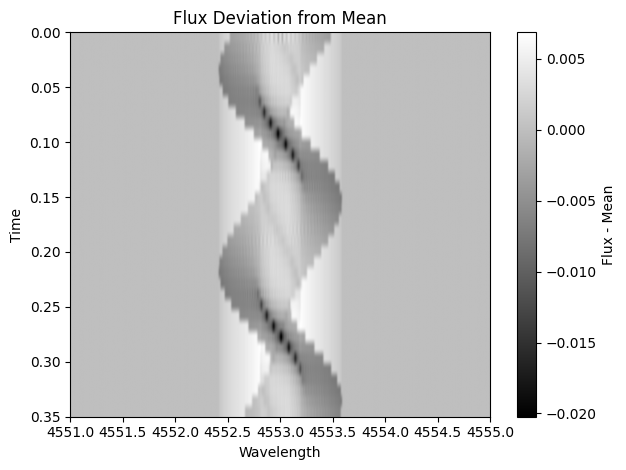

In [15]:
plot_pl.plot_grayscale(wavelength_df=gauss_morecells_df)

In [ ]:
prof_toml_string_morecells = utils.make_profile_input(star=star_morecells,wavelength_range=wl_range)
interp_morecells_df = psp.profile(prof_toml_string_morecells,star_morecells)

In [ ]:
plot_pl.plot_grayscale(wavelength_df=gauss_morecells_df)